<a href="https://colab.research.google.com/github/analicepinho/C-lculo-Num-rico/blob/main/CN_AtividadePratica1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

###Atividade Prática 1 - Cálculo Numérico
####Analice Costa Pinho
#####Prof Raquel J. Lobosco

#####Turma NB

In [2]:
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.animation as animation
from IPython.display import Image as IPImage, display
plt.rcParams['figure.dpi'] = 120
plt.rcParams['font.size'] = 10

In [3]:
def erro_absoluto(x_ref, x_aprox):
    return np.abs(x_ref - x_aprox)

def erro_relativo(x_ref, x_aprox):
    return np.abs(x_ref - x_aprox) / np.abs(x_ref)

def erro_percentual(x_ref, x_aprox):
    return erro_relativo(x_ref, x_aprox) * 100.0

def truncar(x, n):
    fator = 10.0 ** n
    return math.trunc(x * fator) / fator

def arredondar(x, n):
    return round(x, n)

Parte A - truncamento e arredondamento

,Variável,Ref,n,Trunc,Ea_Trunc,Er_Trunc,Ep_Trunc(%),Arred,Ea_Arred,Er_Arred,Ep_Arred(%)
0,x1,3.141593,0,3.0000,0.141593,4.507034e-02,4.507034,3.0000,0.141593,4.507034e-02,4.507034
1,x1,3.141593,1,3.1000,0.041593,1.323935e-02,1.323935,3.1000,0.041593,1.323935e-02,1.323935
2,x1,3.141593,2,3.1400,0.001593,5.069562e-04,0.050696,3.1400,0.001593,5.069562e-04,0.050696
3,x1,3.141593,3,3.1410,0.000593,1.886464e-04,0.018865,3.1420,0.000407,1.296635e-04,0.012966
4,x1,3.141593,4,3.1415,0.000093,2.949141e-05,0.002949,3.1416,0.000007,2.339578e-06,0.000234
5,x2,98.765430,0,98.0000,0.765430,7.749979e-03,0.774998,99.0000,0.234570,2.375021e-03,0.237502
6,x2,98.765430,1,98.7000,0.065430,6.624788e-04,0.066248,98.8000,0.034570,3.500213e-04,0.035002
7,x2,98.765430,2,98.7600,0.005430,5.497875e-05,0.005498,98.7700,0.004570,4.627125e-05,0.004627
8,x2,98.765430,3,98.7650,0.000430,4.353750e-06,0.000435,98.7650,0.000430,4.353750e-06,0.000435
9,x2,98.765430,4,98.7654,0.000030,3.037500e-07,0.000030,98.7654,0.000030,3.037500e-07,0.000030


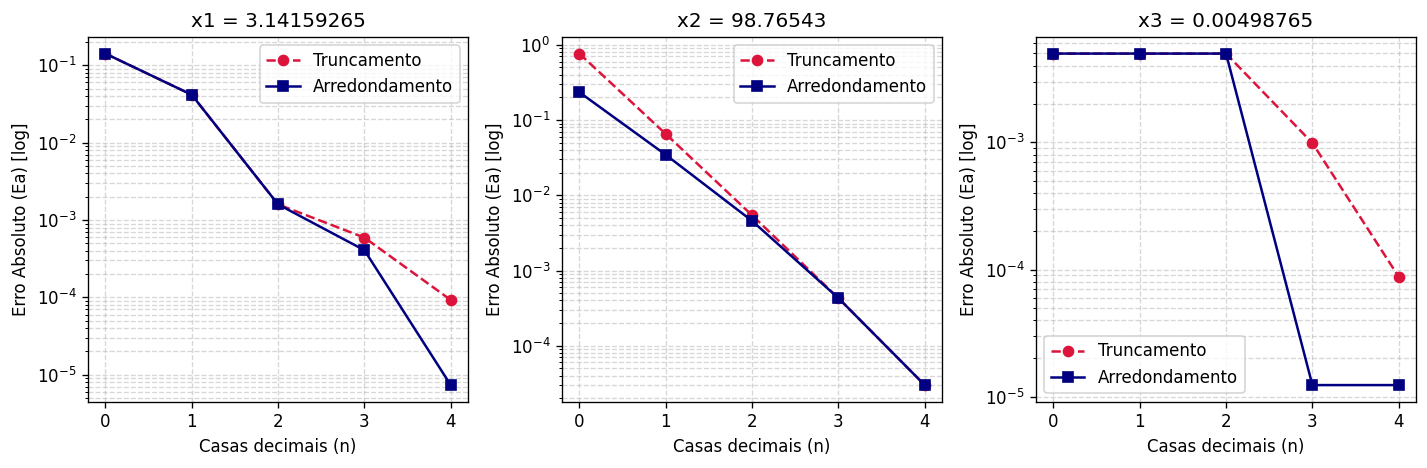

In [4]:
valores_A = {'x1': 3.14159265, 'x2': 98.76543, 'x3': 0.00498765}
casas = [0, 1, 2, 3, 4]

linhas_tabela_A = []

for nome, x_ref in valores_A.items():
    for n in casas:
        x_trunc = truncar(x_ref, n)
        x_arred = arredondar(x_ref, n)

        # Erros Truncamento
        ea_t = erro_absoluto(x_ref, x_trunc)
        er_t = erro_relativo(x_ref, x_trunc)
        ep_t = erro_percentual(x_ref, x_trunc)

        # Erros Arredondamento
        ea_a = erro_absoluto(x_ref, x_arred)
        er_a = erro_relativo(x_ref, x_arred)
        ep_a = erro_percentual(x_ref, x_arred)

        linhas_tabela_A.append({
            'Variável': nome, 'Ref': x_ref, 'n': n,
            'Trunc': x_trunc, 'Ea_Trunc': ea_t, 'Er_Trunc': er_t, 'Ep_Trunc(%)': ep_t,
            'Arred': x_arred, 'Ea_Arred': ea_a, 'Er_Arred': er_a, 'Ep_Arred(%)': ep_a
        })

df_A = pd.DataFrame(linhas_tabela_A)
display(df_A)

# Gráfico logarítmico de Ea em função de n
plt.figure(figsize=(12, 4))
for i, (nome, x_ref) in enumerate(valores_A.items(), 1):
    plt.subplot(1, 3, i)
    sub_df = df_A[df_A['Variável'] == nome]
    plt.plot(sub_df['n'], sub_df['Ea_Trunc'], 'o--', label='Truncamento', color='crimson')
    plt.plot(sub_df['n'], sub_df['Ea_Arred'], 's-', label='Arredondamento', color='navy')
    plt.yscale('log')
    plt.xlabel('Casas decimais (n)')
    plt.ylabel('Erro Absoluto (Ea) [log]')
    plt.title(f'{nome} = {x_ref}')
    plt.grid(True, which="both", ls="--", alpha=0.5)
    plt.legend()

plt.tight_layout()
plt.show()

**Arredondar sempre gera erro menor ou igual ao truncamento?**
A partir dos exemplos feitos, conclui-se que sim. Em todos os casos, o erro de arredondamento foi igual (quando o dígito descartado é menor que 5) ou menor.

Parte B - medidas de pressão arterial

In [20]:
fig = plt.figure(figsize=(16, 11), dpi=120)
fig.patch.set_facecolor('#FDFBFC')

gs = fig.add_gridspec(3, 3, height_ratios=[1.1, 1.0, 1.0], hspace=0.35, wspace=0.25)

ax_top = fig.add_subplot(gs[0, :])
ax_top.axis('off')
ax_top.text(0.5, 0.92, 'SÍNTESE VISUAL - ATIVIDADE PRÁTICA I: CÁLCULO NUMÉRICO',
            ha='center', va='center', fontsize=18, fontweight='bold', color='black')

p_m_ref = np.mean(p_medida)
p_m_arr = np.mean(p_arred)
p_m_tru = np.mean(p_trunc)
p_ea_arr, p_er_arr, p_ep_arr = erro_absoluto(p_m_ref, p_m_arr), erro_relativo(p_m_ref, p_m_arr), erro_percentual(p_m_ref, p_m_arr)
p_ea_tru, p_er_tru, p_ep_tru = erro_absoluto(p_m_ref, p_m_tru), erro_relativo(p_m_ref, p_m_tru), erro_percentual(p_m_ref, p_m_tru)

q_m_arr = poiseuille(arredondar(r_ref_mm, 1), L_ref, arredondar(mu_ref, 3), arredondar(dp_ref / 100.0, 0) * 100.0)
q_m_tru = poiseuille(truncar(r_ref_mm, 1), L_ref, truncar(mu_ref, 3), truncar(dp_ref / 100.0, 0) * 100.0)
q_ea_arr, q_er_arr, q_ep_arr = erro_absoluto(Q_ref, q_m_arr), erro_relativo(Q_ref, q_m_arr), erro_percentual(Q_ref, q_m_arr)
q_ea_tru, q_er_tru, q_ep_tru = erro_absoluto(Q_ref, q_m_tru), erro_relativo(Q_ref, q_m_tru), erro_percentual(Q_ref, q_m_tru)

q_n_arr = poiseuille(50.0 * 1e-6, L_nano, mu_nano, dp_nano)
q_n_tru = poiseuille(49.0 * 1e-6, L_nano, mu_nano, dp_nano)
qn_ea_arr, qn_er_arr, qn_ep_arr = erro_absoluto(Q_nano_ref, q_n_arr), erro_relativo(Q_nano_ref, q_n_arr), erro_percentual(Q_nano_ref, q_n_arr)
qn_ea_tru, qn_er_tru, qn_ep_tru = erro_absoluto(Q_nano_ref, q_n_tru), erro_relativo(Q_nano_ref, q_n_tru), erro_percentual(Q_nano_ref, q_n_tru)

cartoes_info = [
    {
        "titulo": "Pressão Arterial Média",
        "ref": f"{p_m_ref:.2f} mmHg",
        "arr_val": f"{p_m_arr:.2f} mmHg",
        "arr_erros": f"Ea: {p_ea_arr:.2f} | Er: {p_er_arr:.4f} | Ep: {p_ep_arr:.2f}%",
        "tru_val": f"{p_m_tru:.2f} mmHg",
        "tru_erros": f"Ea: {p_ea_tru:.2f} | Er: {p_er_tru:.4f} | Ep: {p_ep_tru:.2f}%"
    },
    {
        "titulo": "Vazão Tubo Macro",
        "ref": f"{Q_ref:.3e} m³/s",
        "arr_val": f"{q_m_arr:.3e} m³/s",
        "arr_erros": f"Ea: {q_ea_arr:.2e} | Er: {q_er_arr:.3f} | Ep: {q_ep_arr:.1f}%",
        "tru_val": f"{q_m_tru:.3e} m³/s",
        "tru_erros": f"Ea: {q_ea_tru:.2e} | Er: {q_er_tru:.3f} | Ep: {q_ep_tru:.1f}%"
    },
    {
        "titulo": "Vazão Nanocateter",
        "ref": f"{Q_nano_ref:.3e} m³/s",
        "arr_val": f"{q_n_arr:.3e} m³/s",
        "arr_erros": f"Ea: {qn_ea_arr:.2e} | Er: {qn_er_arr:.3f} | Ep: {qn_ep_arr:.1f}%",
        "tru_val": f"{q_n_tru:.3e} m³/s",
        "tru_erros": f"Ea: {qn_ea_tru:.2e} | Er: {qn_er_tru:.3f} | Ep: {qn_ep_tru:.1f}%"
    }
]

for idx, c in enumerate(cartoes_info):
    rect = plt.Rectangle((idx * 0.34 + 0.01, 0.0), 0.31, 0.82,
                         facecolor='#FCE4EC', edgecolor='#C2185B', lw=1.5, transform=ax_top.transAxes)
    ax_top.add_patch(rect)

    x_c = idx * 0.34 + 0.165
    ax_top.text(x_c, 0.72, c["titulo"], ha='center', va='center', fontsize=11, fontweight='bold', color='#880E4F', transform=ax_top.transAxes)
    ax_top.text(x_c, 0.58, f"Ref: {c['ref']}", ha='center', va='center', fontsize=9.5, fontweight='bold', color='black', transform=ax_top.transAxes)

    texto_bloco = (
        f"• Arred: {c['arr_val']}\n  ({c['arr_erros']})\n"
        f"• Trunc: {c['tru_val']}\n  ({c['tru_erros']})"
    )
    ax_top.text(x_c, 0.28, texto_bloco, ha='center', va='center', fontsize=8.2, family='monospace', color='#37474F', transform=ax_top.transAxes)

ax_trunc = fig.add_subplot(gs[1, 0])
sub_x1 = df_A[df_A['Variável'] == 'x1']
ax_trunc.plot(sub_x1['n'], sub_x1['Ea_Trunc'], 'o--', label='Trunc.', color='crimson')
ax_trunc.plot(sub_x1['n'], sub_x1['Ea_Arred'], 's-', label='Arred.', color='navy')
ax_trunc.set_yscale('log')
ax_trunc.set_title('Truncamento vs Arredondamento ($x_1$)', fontsize=11, fontweight='bold')
ax_trunc.set_xlabel('Casas decimais (n)')
ax_trunc.set_ylabel('Ea (log)')
ax_trunc.grid(True, alpha=0.3)
ax_trunc.legend(fontsize=9)

ax_sens = fig.add_subplot(gs[1, 1])
ax_sens.plot(r_faixa_mm, Q_faixa_ref*1e6, color='black', lw=2, label='Q Ref')
ax_sens.set_title('Sensibilidade da Vazão ($Q \\propto r^4$)', fontsize=11, fontweight='bold')
ax_sens.set_xlabel('Raio (mm)')
ax_sens.set_ylabel('Q ($cm^3/s$)')
ax_sens.grid(True, alpha=0.3)
ax_sens.legend(fontsize=9)

ax_nano = fig.add_subplot(gs[1, 2])
ax_nano.plot(delta_r_nm, Ep_max, color='tab:orange', lw=2)
ax_nano.set_title(r'Erro Percentual Máx no Nanocateter', fontsize=11, fontweight='bold')
ax_nano.set_xlabel(r'$\Delta r$ (nm)')
ax_nano.set_ylabel('Erro Percentual (%)')
ax_nano.grid(True, alpha=0.3)

ax_prec1 = fig.add_subplot(gs[2, 0])
ax_prec1.bar(['float32', 'float64'], [np.finfo(np.float32).eps, np.finfo(np.float64).eps], color=['#F48FB1', '#AD1457'], width=0.4)
ax_prec1.set_yscale('log')
ax_prec1.set_title('Epsilon de Máquina ($\epsilon$)', fontsize=11, fontweight='bold')
ax_prec1.set_ylabel('Epsilon')
ax_prec1.grid(axis='y', alpha=0.3)

ax_prec2 = fig.add_subplot(gs[2, 1:])
ax_prec2.plot(deltas_teste, [abs(poiseuille(r_nano*(1+d)*1e3, L_nano, mu_nano, dp_nano) - poiseuille(r_nano*1e3, L_nano, mu_nano, dp_nano))/poiseuille(r_nano*1e3, L_nano, mu_nano, dp_nano) - ((1+d)**4 - 1)) for d in deltas_teste], 'o-', color='#C2185B', lw=2)
ax_prec2.set_xscale('log')
ax_prec2.set_yscale('log')
ax_prec2.set_title(r'Cancelamento Catastrófico: $|\delta_1 - \delta_2|$ vs $\Delta r / r$', fontsize=11, fontweight='bold')
ax_prec2.set_xlabel(r'$\Delta r / r$ (log)')
ax_prec2.set_ylabel(r'Diferença Numérica $|\delta_1 - \delta_2|$ (log)')
ax_prec2.grid(True, which='both', alpha=0.3)

plt.savefig('sintese_visual.png', dpi=120, bbox_inches='tight')
plt.show()

<>:98: SyntaxWarning: invalid escape sequence '\e'
<>:98: SyntaxWarning: invalid escape sequence '\e'
/tmp/ipykernel_2282/3551959086.py:98: SyntaxWarning: invalid escape sequence '\e'
  ax_prec1.set_title('Epsilon de Máquina ($\epsilon$)', fontsize=11, fontweight='bold')


SyntaxError: closing parenthesis ')' does not match opening parenthesis '[' (3551959086.py, line 103)

**Explique se a representação inteira é suficiente para preservar a média e a variabilidade
desta pequena amostra.**
A série de números arredondados preservou bem a média, enquanto a série de números truncados não foi suficiente em preservar a média.
Em relação a preservar a variabilidade, nenhuma das séries foi suficiente, demonstrando maior ou menor amplitude e aumento do desvio padrão. Logo, para essa amostra, medidas com mais algarismos representam melhor os dados.


Parte C - vazão em um tubo de pequeno diâmetro.

,Cenário,r (mm),μ (Pa.s),∆p (Pa),Q (m³/s),Ea (m³/s),Er,Ep (%)
0,1. Valores Fornecidos,0.8,0.0035,1200.0,2.757421e-07,0.000000e+00,0.000000,0.000000
1,2.1 r Arredondado (1 casa em mm),0.8,0.0035,1200.0,2.757421e-07,0.000000e+00,0.000000,0.000000
2,2.2 r Truncado (1 casa em mm),0.8,0.0035,1200.0,2.757421e-07,0.000000e+00,0.000000,0.000000
3,3.1 μ Arredondada (3 casas em Pa.s),0.8,0.0040,1200.0,2.412743e-07,3.446776e-08,0.125000,12.500000
4,3.2 μ Truncada (3 casas em Pa.s),0.8,0.0030,1200.0,3.216991e-07,4.595701e-08,0.166667,16.666667
5,4.1 ∆p Arredondada (centenas de Pa),0.8,0.0035,1200.0,2.757421e-07,0.000000e+00,0.000000,0.000000
6,4.2 ∆p Truncada (centenas de Pa),0.8,0.0035,1200.0,2.757421e-07,0.000000e+00,0.000000,0.000000
7,5.1 Todas Aproximações Arredondadas,0.8,0.0040,1200.0,2.412743e-07,3.446776e-08,0.125000,12.500000
8,5.2 Todas Aproximações Truncadas,0.8,0.0030,1200.0,3.216991e-07,4.595701e-08,0.166667,16.666667


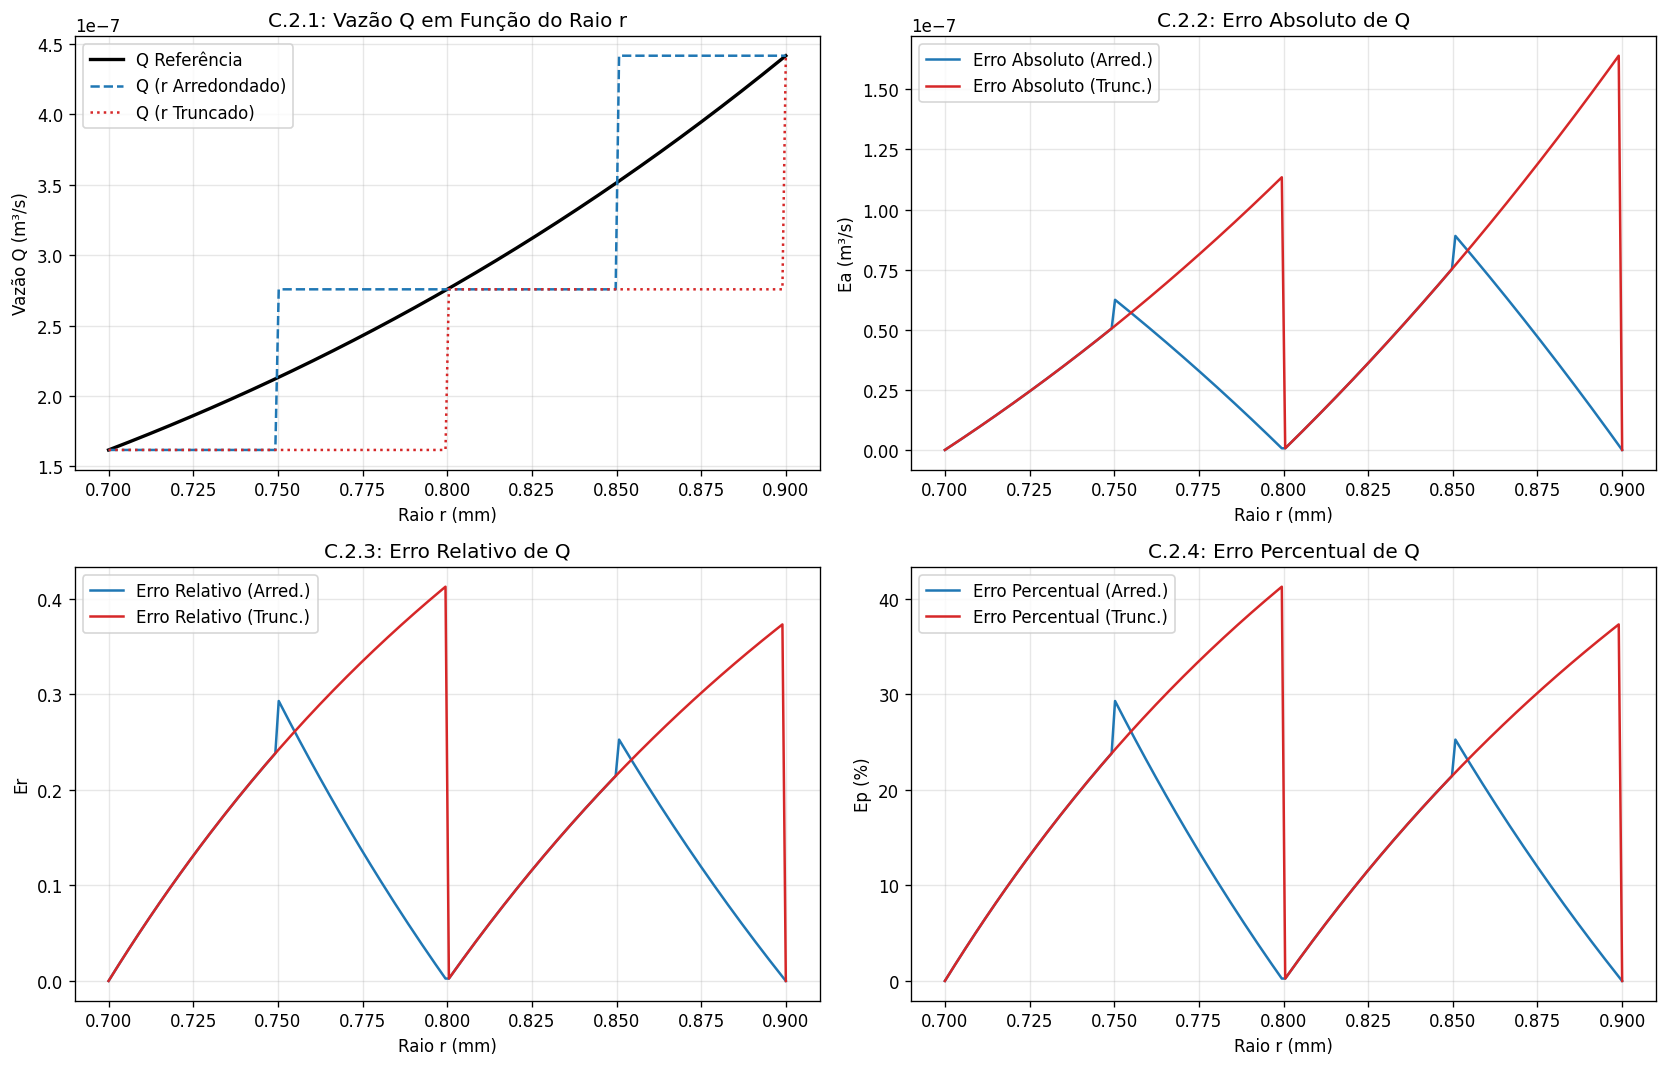

In [9]:
def poiseuille(r_mm, L, mu, dp):
    r_m = r_mm * 1e-3
    return (np.pi * (r_m**4) * dp) / (8.0 * mu * L)

r_ref_mm = 0.80
L_ref    = 0.20
mu_ref   = 3.5e-3
dp_ref   = 1200.0
dp_ref_hpa = dp_ref / 100.0

Q_ref = poiseuille(r_ref_mm, L_ref, mu_ref, dp_ref)

cenarios_C1 = [
    ("1. Valores Fornecidos",r_ref_mm,mu_ref,dp_ref),
    ("2.1 r Arredondado (1 casa em mm)",arredondar(r_ref_mm, 1),mu_ref,dp_ref),
    ("2.2 r Truncado (1 casa em mm)",truncar(r_ref_mm, 1),mu_ref,dp_ref),
    ("3.1 μ Arredondada (3 casas em Pa.s)",r_ref_mm,arredondar(mu_ref, 3),dp_ref),
    ("3.2 μ Truncada (3 casas em Pa.s)",r_ref_mm,truncar(mu_ref, 3),dp_ref),
    ("4.1 ∆p Arredondada (centenas de Pa)",r_ref_mm,mu_ref,arredondar(dp_ref_hpa,0) * 100.0),
    ("4.2 ∆p Truncada (centenas de Pa)",r_ref_mm,mu_ref,truncar(dp_ref_hpa,0) * 100.0),
    ("5.1 Todas Aproximações Arredondadas",arredondar(r_ref_mm, 1),arredondar(mu_ref, 3),arredondar(dp_ref_hpa,0) * 100.0),
    ("5.2 Todas Aproximações Truncadas",truncar(r_ref_mm, 1),truncar(mu_ref, 3),truncar(dp_ref_hpa,0) * 100.0)
]

tabela_C1 = []
for nome, r_val_mm, mu_val, dp_val in cenarios_C1:
    q_calc = poiseuille(r_val_mm, L_ref, mu_val, dp_val)
    tabela_C1.append({
        'Cenário': nome,
        'r (mm)': r_val_mm,
        'μ (Pa.s)': mu_val,
        '∆p (Pa)': dp_val,
        'Q (m³/s)': q_calc,
        'Ea (m³/s)': erro_absoluto(Q_ref, q_calc),
        'Er': erro_relativo(Q_ref, q_calc),
        'Ep (%)': erro_percentual(Q_ref, q_calc)
    })

df_C1 = pd.DataFrame(tabela_C1)
display(df_C1)

r_faixa_mm = np.linspace(0.70, 0.90, 200)

r_faixa_arred_mm = np.array([arredondar(val, 1) for val in r_faixa_mm])
r_faixa_trunc_mm = np.array([truncar(val, 1) for val in r_faixa_mm])

Q_faixa_ref   = poiseuille(r_faixa_mm, L_ref, mu_ref, dp_ref)
Q_faixa_arred = poiseuille(r_faixa_arred_mm, L_ref, mu_ref, dp_ref)
Q_faixa_trunc = poiseuille(r_faixa_trunc_mm, L_ref, mu_ref, dp_ref)

ea_arred = erro_absoluto(Q_faixa_ref, Q_faixa_arred)
ea_trunc = erro_absoluto(Q_faixa_ref, Q_faixa_trunc)

er_arred = erro_relativo(Q_faixa_ref, Q_faixa_arred)
er_trunc = erro_relativo(Q_faixa_ref, Q_faixa_trunc)

ep_arred = erro_percentual(Q_faixa_ref, Q_faixa_arred)
ep_trunc = erro_percentual(Q_faixa_ref, Q_faixa_trunc)

fig, axs = plt.subplots(2, 2, figsize=(14, 9))

axs[0, 0].plot(r_faixa_mm, Q_faixa_ref, label='Q Referência', color='black', lw=2)
axs[0, 0].plot(r_faixa_mm, Q_faixa_arred, '--', label='Q (r Arredondado)', color='tab:blue')
axs[0, 0].plot(r_faixa_mm, Q_faixa_trunc, ':', label='Q (r Truncado)', color='tab:red')
axs[0, 0].set_xlabel('Raio r (mm)')
axs[0, 0].set_ylabel('Vazão Q (m³/s)')
axs[0, 0].set_title('C.2.1: Vazão Q em Função do Raio r')
axs[0, 0].legend()
axs[0, 0].grid(True, alpha=0.3)

axs[0, 1].plot(r_faixa_mm, ea_arred, label='Erro Absoluto (Arred.)', color='tab:blue')
axs[0, 1].plot(r_faixa_mm, ea_trunc, label='Erro Absoluto (Trunc.)', color='tab:red')
axs[0, 1].set_xlabel('Raio r (mm)')
axs[0, 1].set_ylabel('Ea (m³/s)')
axs[0, 1].set_title('C.2.2: Erro Absoluto de Q')
axs[0, 1].legend()
axs[0, 1].grid(True, alpha=0.3)

axs[1, 0].plot(r_faixa_mm, er_arred, label='Erro Relativo (Arred.)', color='tab:blue')
axs[1, 0].plot(r_faixa_mm, er_trunc, label='Erro Relativo (Trunc.)', color='tab:red')
axs[1, 0].set_xlabel('Raio r (mm)')
axs[1, 0].set_ylabel('Er')
axs[1, 0].set_title('C.2.3: Erro Relativo de Q')
axs[1, 0].legend()
axs[1, 0].grid(True, alpha=0.3)

axs[1, 1].plot(r_faixa_mm, ep_arred, label='Erro Percentual (Arred.)', color='tab:blue')
axs[1, 1].plot(r_faixa_mm, ep_trunc, label='Erro Percentual (Trunc.)', color='tab:red')
axs[1, 1].set_xlabel('Raio r (mm)')
axs[1, 1].set_ylabel('Ep (%)')
axs[1, 1].set_title('C.2.4: Erro Percentual de Q')
axs[1, 1].legend()
axs[1, 1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

**Explique por que o erro no raio é amplificado na vazão.**

Como Q está relacionado diretamente a r⁴, erros na medição de r são multiplicados por aproximadamente 4 no cálculo da vazão Q.

Parte D – escoamento em um nanocateter

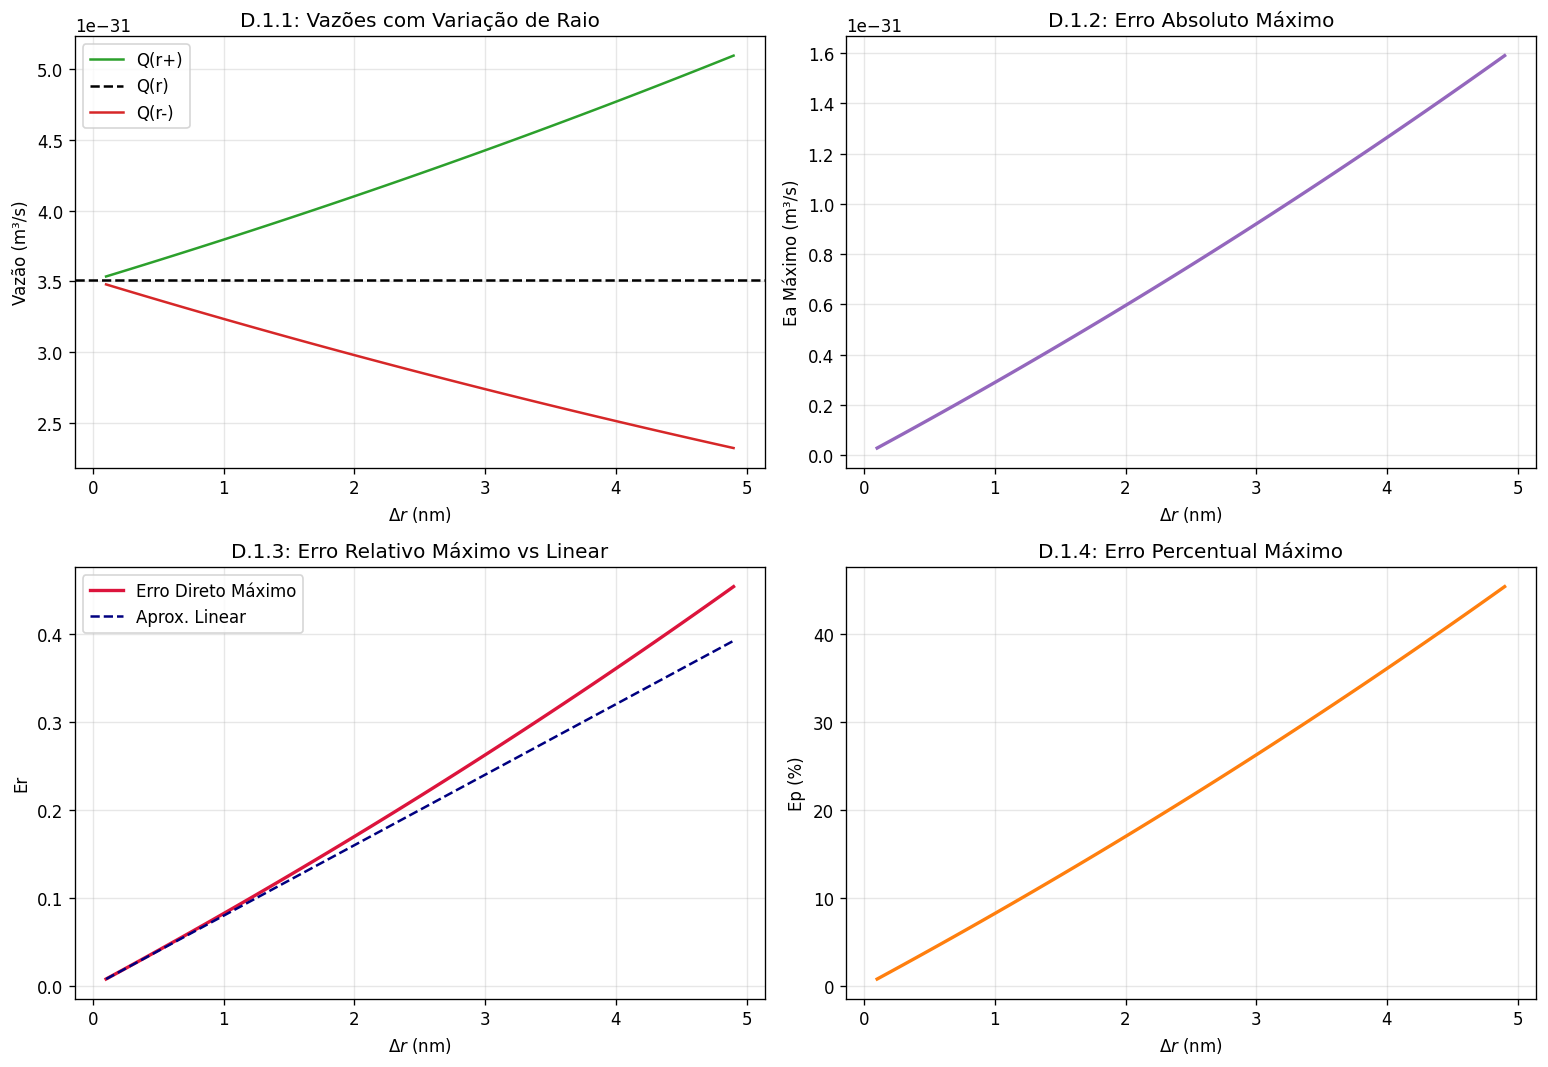

D.2 Precisão Numérica
r^4 (float32): 6.2500003960e-30 | eps float32: 1.1920928955078125e-07
r^4 (float64): 6.2500000000e-30 | eps float64: 2.220446049250313e-16
Q (float32): 3.5062423237e-19 m³/s
Q (float64): 3.5062418009e-19 m³/s
Diferença Absoluta: 5.2286276892e-26 m³/s | Diferença Relativa: 1.4912342006e-07

 delta_1 vs delta_2
dr/r = 1.0e-01 | delta_1 = 4.6410000000e-01 | delta_2 = 4.6410000000e-01 | Dif = 9.99e-16
dr/r = 1.0e-02 | delta_1 = 4.0604010000e-02 | delta_2 = 4.0604010000e-02 | Dif = 7.36e-16
dr/r = 1.0e-03 | delta_1 = 4.0060040010e-03 | delta_2 = 4.0060040010e-03 | Dif = 1.91e-17
dr/r = 1.0e-04 | delta_1 = 4.0006000400e-04 | delta_2 = 4.0006000400e-04 | Dif = 4.27e-17
dr/r = 1.0e-05 | delta_1 = 4.0000600004e-05 | delta_2 = 4.0000600004e-05 | Dif = 5.17e-16
dr/r = 1.0e-06 | delta_1 = 4.0000059997e-06 | delta_2 = 4.0000059998e-06 | Dif = 6.74e-17
dr/r = 1.0e-07 | delta_1 = 4.0000005969e-07 | delta_2 = 4.0000006019e-07 | Dif = 4.92e-16
dr/r = 1.0e-08 | delta_1 = 4.00000003

In [17]:
r_nano = 50e-9
L_nano = 10e-6
mu_nano = 3.5e-3
dp_nano = 5000.0

Q_nano_ref = poiseuille(r_nano, L_nano, mu_nano, dp_nano)

delta_r_nm = np.arange(0.1, 5.0, 0.1)
delta_r_m = delta_r_nm * 1e-9

r_menos = r_nano - delta_r_m
r_mais = r_nano + delta_r_m

Q_menos = poiseuille(r_menos, L_nano, mu_nano, dp_nano)
Q_mais = poiseuille(r_mais, L_nano, mu_nano, dp_nano)

Ea_max = np.maximum(np.abs(Q_nano_ref - Q_menos), np.abs(Q_nano_ref - Q_mais))
Er_max = Ea_max / Q_nano_ref
Ep_max = Er_max * 100.0

aprox_linear_Er = 4.0 * (delta_r_m / r_nano)

fig, axs = plt.subplots(2, 2, figsize=(13, 9))

axs[0, 0].plot(delta_r_nm, Q_mais, label=r'Q(r+)', color='tab:green')
axs[0, 0].axhline(Q_nano_ref, label=r'Q(r)', color='black', linestyle='--')
axs[0, 0].plot(delta_r_nm, Q_menos, label=r'Q(r-)', color='tab:red')
axs[0, 0].set_xlabel(r'$\Delta r$ (nm)')
axs[0, 0].set_ylabel('Vazão (m³/s)')
axs[0, 0].set_title('D.1.1: Vazões com Variação de Raio')
axs[0, 0].legend()
axs[0, 0].grid(True, alpha=0.3)

axs[0, 1].plot(delta_r_nm, Ea_max, color='tab:purple', lw=2)
axs[0, 1].set_xlabel(r'$\Delta r$ (nm)')
axs[0, 1].set_ylabel('Ea Máximo (m³/s)')
axs[0, 1].set_title('D.1.2: Erro Absoluto Máximo')
axs[0, 1].grid(True, alpha=0.3)

axs[1, 0].plot(delta_r_nm, Er_max, label='Erro Direto Máximo', color='crimson', lw=2)
axs[1, 0].plot(delta_r_nm, aprox_linear_Er, '--', label=r'Aprox. Linear', color='navy')
axs[1, 0].set_xlabel(r'$\Delta r$ (nm)')
axs[1, 0].set_ylabel('Er')
axs[1, 0].set_title('D.1.3: Erro Relativo Máximo vs Linear')
axs[1, 0].legend()
axs[1, 0].grid(True, alpha=0.3)

axs[1, 1].plot(delta_r_nm, Ep_max, color='tab:orange', lw=2)
axs[1, 1].set_xlabel(r'$\Delta r$ (nm)')
axs[1, 1].set_ylabel('Ep (%)')
axs[1, 1].set_title('D.1.4: Erro Percentual Máximo')
axs[1, 1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


r_32 = np.float32(50e-9)
r_64 = np.float64(50e-9)
L_32, L_64 = np.float32(10e-6), np.float64(10e-6)
mu_32, mu_64 = np.float32(3.5e-3), np.float64(3.5e-3)
dp_32, dp_64 = np.float32(5000.0), np.float64(5000.0)

r4_32 = r_32**4
r4_64 = r_64**4

Q_32 = (np.float32(np.pi) * r4_32 * dp_32) / (np.float32(8.0) * mu_32 * L_32)
Q_64 = (np.float64(np.pi) * r4_64 * dp_64) / (np.float64(8.0) * mu_64 * L_64)

diff_abs_Q = np.abs(Q_64 - Q_32)
diff_rel_Q = diff_abs_Q / np.abs(Q_64)

print(f"D.2 Precisão Numérica")
print(f"r^4 (float32): {r4_32:.10e} | eps float32: {np.finfo(np.float32).eps}")
print(f"r^4 (float64): {r4_64:.10e} | eps float64: {np.finfo(np.float64).eps}")
print(f"Q (float32): {Q_32:.10e} m³/s")
print(f"Q (float64): {Q_64:.10e} m³/s")
print(f"Diferença Absoluta: {diff_abs_Q:.10e} m³/s | Diferença Relativa: {diff_rel_Q:.10e}")

deltas_teste = np.logspace(-1, -8, 8)
print("\n delta_1 vs delta_2")
for d_frac in deltas_teste:
    dr_local = d_frac * r_nano
    q_mais_local = poiseuille(r_nano + dr_local, L_nano, mu_nano, dp_nano)
    delta_1 = (q_mais_local - Q_nano_ref) / Q_nano_ref
    delta_2 = (1.0 + d_frac)**4 - 1.0
    print(f"dr/r = {d_frac:.1e} | delta_1 = {delta_1:.10e} | delta_2 = {delta_2:.10e} | Dif = {abs(delta_1-delta_2):.2e}")

Parte E – síntese visual

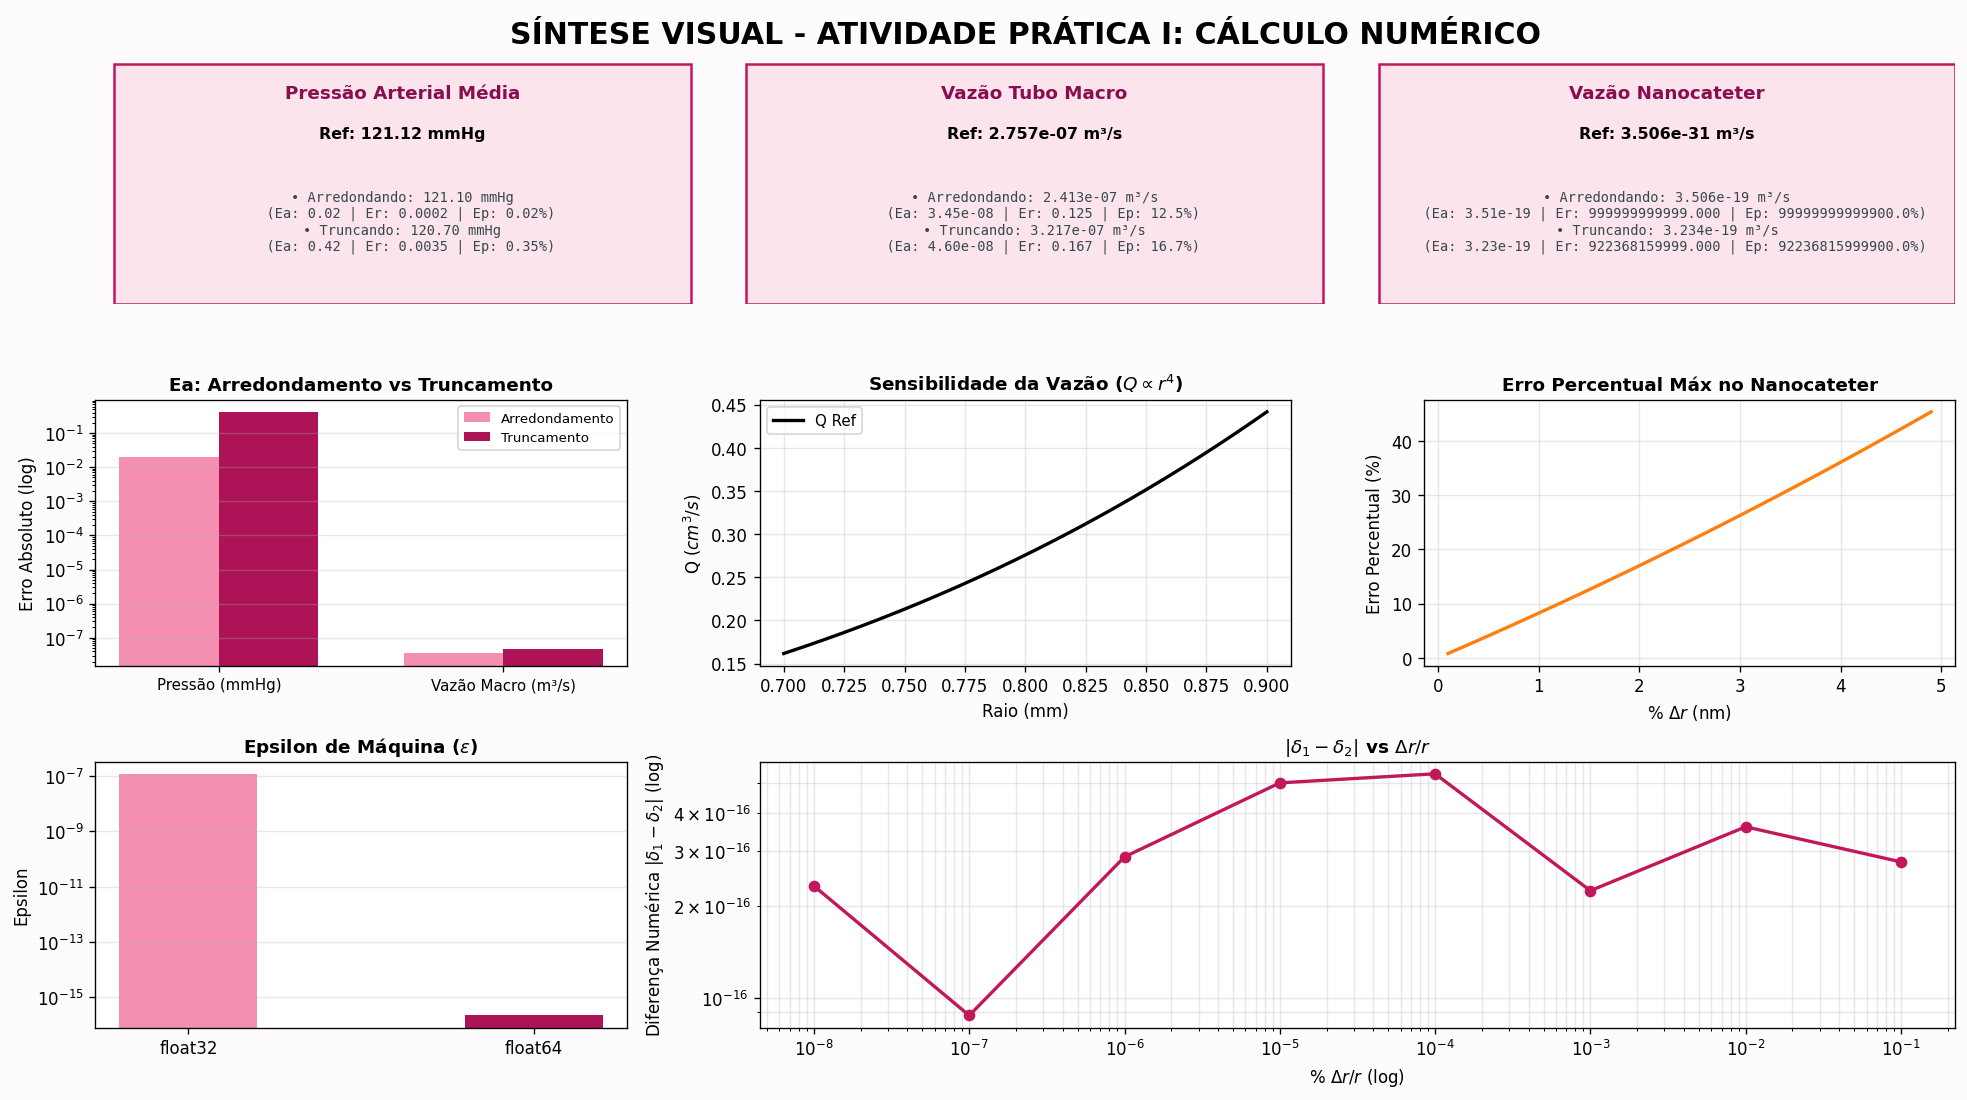

In [46]:
fig = plt.figure(figsize=(20, 11), dpi=120)
fig.patch.set_facecolor('#FDFBFC')

gs = fig.add_gridspec(3, 3, height_ratios=[1.1, 1.0, 1.0], hspace=0.35, wspace=0.25)

ax_top = fig.add_subplot(gs[0, :])
ax_top.axis('off')
ax_top.text(0.5, 0.92, 'SÍNTESE VISUAL - ATIVIDADE PRÁTICA I: CÁLCULO NUMÉRICO',
            ha='center', va='center', fontsize=18, fontweight='bold', color='black')

p_m_ref = np.mean(p_medida)
p_m_arr = np.mean(p_arred)
p_m_tru = np.mean(p_trunc)
p_ea_arr, p_er_arr, p_ep_arr = erro_absoluto(p_m_ref, p_m_arr), erro_relativo(p_m_ref, p_m_arr), erro_percentual(p_m_ref, p_m_arr)
p_ea_tru, p_er_tru, p_ep_tru = erro_absoluto(p_m_ref, p_m_tru), erro_relativo(p_m_ref, p_m_tru), erro_percentual(p_m_ref, p_m_tru)

q_m_arr = poiseuille(arredondar(r_ref_mm, 1), L_ref, arredondar(mu_ref, 3), arredondar(dp_ref / 100.0, 0) * 100.0)
q_m_tru = poiseuille(truncar(r_ref_mm, 1), L_ref, truncar(mu_ref, 3), truncar(dp_ref / 100.0, 0) * 100.0)
q_ea_arr, q_er_arr, q_ep_arr = erro_absoluto(Q_ref, q_m_arr), erro_relativo(Q_ref, q_m_arr), erro_percentual(Q_ref, q_m_arr)
q_ea_tru, q_er_tru, q_ep_tru = erro_absoluto(Q_ref, q_m_tru), erro_relativo(Q_ref, q_m_tru), erro_percentual(Q_ref, q_m_tru)

q_n_arr = poiseuille(50.0 * 1e-6, L_nano, mu_nano, dp_nano)
q_n_tru = poiseuille(49.0 * 1e-6, L_nano, mu_nano, dp_nano)
qn_ea_arr, qn_er_arr, qn_ep_arr = erro_absoluto(Q_nano_ref, q_n_arr), erro_relativo(Q_nano_ref, q_n_arr), erro_percentual(Q_nano_ref, q_n_arr)
qn_ea_tru, qn_er_tru, qn_ep_tru = erro_absoluto(Q_nano_ref, q_n_tru), erro_relativo(Q_nano_ref, q_n_tru), erro_percentual(Q_nano_ref, q_n_tru)

cartoes_info = [
    {
        "titulo": "Pressão Arterial Média",
        "ref": f"{p_m_ref:.2f} mmHg",
        "arr_val": f"{p_m_arr:.2f} mmHg",
        "arr_erros": f"Ea: {p_ea_arr:.2f} | Er: {p_er_arr:.4f} | Ep: {p_ep_arr:.2f}%",
        "tru_val": f"{p_m_tru:.2f} mmHg",
        "tru_erros": f"Ea: {p_ea_tru:.2f} | Er: {p_er_tru:.4f} | Ep: {p_ep_tru:.2f}%"
    },
    {
        "titulo": "Vazão Tubo Macro",
        "ref": f"{Q_ref:.3e} m³/s",
        "arr_val": f"{q_m_arr:.3e} m³/s",
        "arr_erros": f"Ea: {q_ea_arr:.2e} | Er: {q_er_arr:.3f} | Ep: {q_ep_arr:.1f}%",
        "tru_val": f"{q_m_tru:.3e} m³/s",
        "tru_erros": f"Ea: {q_ea_tru:.2e} | Er: {q_er_tru:.3f} | Ep: {q_ep_tru:.1f}%"
    },
    {
        "titulo": "Vazão Nanocateter",
        "ref": f"{Q_nano_ref:.3e} m³/s",
        "arr_val": f"{q_n_arr:.3e} m³/s",
        "arr_erros": f"Ea: {qn_ea_arr:.2e} | Er: {qn_er_arr:.3f} | Ep: {qn_ep_arr:.1f}%",
        "tru_val": f"{q_n_tru:.3e} m³/s",
        "tru_erros": f"Ea: {qn_ea_tru:.2e} | Er: {qn_er_tru:.3f} | Ep: {qn_ep_tru:.1f}%"
    }
]

for idx, c in enumerate(cartoes_info):
    rect = plt.Rectangle((idx * 0.34 + 0.01, 0.0), 0.31, 0.82,
                         facecolor='#FCE4EC', edgecolor='#C2185B', lw=1.5, transform=ax_top.transAxes)
    ax_top.add_patch(rect)

    x_c = idx * 0.34 + 0.165
    ax_top.text(x_c, 0.72, c["titulo"], ha='center', va='center', fontsize=11, fontweight='bold', color='#880E4F', transform=ax_top.transAxes)
    ax_top.text(x_c, 0.58, f"Ref: {c['ref']}", ha='center', va='center', fontsize=9.5, fontweight='bold', color='black', transform=ax_top.transAxes)

    texto_bloco = (
        f"• Arredondando: {c['arr_val']}\n  ({c['arr_erros']})\n"
        f"• Truncando: {c['tru_val']}\n  ({c['tru_erros']})"
    )
    ax_top.text(x_c, 0.28, texto_bloco, ha='center', va='center', fontsize=8.2, family='monospace', color='#37474F', transform=ax_top.transAxes)

ax_trunc = fig.add_subplot(gs[1, 0])
categorias_ex = ['Pressão (mmHg)', 'Vazão Macro (m³/s)']
x_pos = np.arange(len(categorias_ex))
w_bar = 0.35

ax_trunc.bar(x_pos - w_bar/2, [p_ea_arr, q_ea_arr], width=w_bar, label='Arredondamento', color='#F48FB1')
ax_trunc.bar(x_pos + w_bar/2, [p_ea_tru, q_ea_tru], width=w_bar, label='Truncamento', color='#AD1457')
ax_trunc.set_yscale('log')
ax_trunc.set_xticks(x_pos)
ax_trunc.set_xticklabels(categorias_ex, fontsize=9)
ax_trunc.set_title('Ea: Arredondamento vs Truncamento', fontsize=11, fontweight='bold')
ax_trunc.set_ylabel('Erro Absoluto (log)')
ax_trunc.grid(axis='y', alpha=0.3)
ax_trunc.legend(fontsize=8)

ax_sens = fig.add_subplot(gs[1, 1])
ax_sens.plot(r_faixa_mm, Q_faixa_ref*1e6, color='black', lw=2, label='Q Ref')
ax_sens.set_title(r'Sensibilidade da Vazão ($Q \propto r^4$)', fontsize=11, fontweight='bold')
ax_sens.set_xlabel('Raio (mm)')
ax_sens.set_ylabel('Q ($cm^3/s$)')
ax_sens.grid(True, alpha=0.3)
ax_sens.legend(fontsize=9)

ax_nano = fig.add_subplot(gs[1, 2])
ax_nano.plot(delta_r_nm, Ep_max, color='tab:orange', lw=2)
ax_nano.set_title(r'Erro Percentual Máx no Nanocateter', fontsize=11, fontweight='bold')
ax_nano.set_xlabel(r'% $\Delta r$ (nm)')
ax_nano.set_ylabel('Erro Percentual (%)')
ax_nano.grid(True, alpha=0.3)

ax_prec1 = fig.add_subplot(gs[2, 0])
ax_prec1.bar(['float32', 'float64'], [np.finfo(np.float32).eps, np.finfo(np.float64).eps], color=['#F48FB1', '#AD1457'], width=0.4)
ax_prec1.set_yscale('log')
ax_prec1.set_title(r'Epsilon de Máquina ($\epsilon$)', fontsize=11, fontweight='bold')
ax_prec1.set_ylabel('Epsilon')
ax_prec1.grid(axis='y', alpha=0.3)

ax_prec2 = fig.add_subplot(gs[2, 1:])
ax_prec2.plot(deltas_teste, [abs((poiseuille(r_nano*(1+d)*1e3, L_nano, mu_nano, dp_nano) - poiseuille(r_nano*1e3, L_nano, mu_nano, dp_nano))/poiseuille(r_nano*1e3, L_nano, mu_nano, dp_nano) - ((1+d)**4 - 1)) for d in deltas_teste], 'o-', color='#C2185B', lw=2)
ax_prec2.set_xscale('log')
ax_prec2.set_yscale('log')
ax_prec2.set_title(r'$|\delta_1 - \delta_2|$ vs $\Delta r / r$', fontsize=11, fontweight='bold')
ax_prec2.set_xlabel(r'% $\Delta r/r$ (log)')
ax_prec2.set_ylabel(r'Diferença Numérica $|\delta_1 - \delta_2|$ (log)')
ax_prec2.grid(True, which='both', alpha=0.3)

plt.savefig('sintese_visual.png', dpi=120, bbox_inches='tight')
plt.show()

GIF demonstrativo


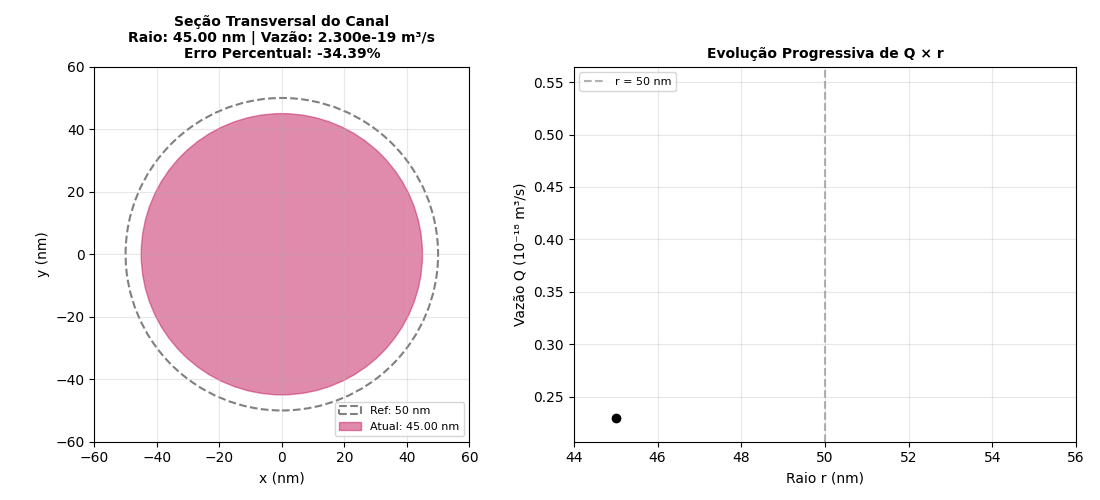

In [28]:
def poiseuille_si(r_m, L_m, mu_pas, dp_pa):
    return (np.pi * (r_m**4) * dp_pa) / (8.0 * mu_pas * L_m)

r_ref_nano_m = 50e-9
L_nano_m = 10e-6
mu_nano_pas = 3.5e-3
dp_nano_pa = 5000.0

Q_nano_ref_m3s = poiseuille_si(r_ref_nano_m, L_nano_m, mu_nano_pas, dp_nano_pa)

raios_gif_nm = np.linspace(45.0, 55.0, 50)
raios_gif_m = raios_gif_nm * 1e-9
vazoes_gif_m3s = poiseuille_si(raios_gif_m, L_nano_m, mu_nano_pas, dp_nano_pa)
erros_pct_gif = ((vazoes_gif_m3s - Q_nano_ref_m3s) / Q_nano_ref_m3s) * 100.0

fig_anim, (ax_canal, ax_curva) = plt.subplots(1, 2, figsize=(11, 5), dpi=100)

def atualizar_frame(i):
    ax_canal.clear()
    ax_curva.clear()

    r_atual_nm = raios_gif_nm[i]
    q_atual_m3s = vazoes_gif_m3s[i]
    ep_atual = erros_pct_gif[i]

    circulo_ref = plt.Circle((0, 0), 50.0, color='gray', fill=False, linestyle='--', lw=1.5, label='Ref: 50 nm')
    circulo_atual = plt.Circle((0, 0), r_atual_nm, color='#C2185B', alpha=0.5, label=f'Atual: {r_atual_nm:.2f} nm')
    ax_canal.add_patch(circulo_ref)
    ax_canal.add_patch(circulo_atual)
    ax_canal.set_xlim(-60, 60)
    ax_canal.set_ylim(-60, 60)
    ax_canal.set_aspect('equal')
    ax_canal.set_xlabel('x (nm)')
    ax_canal.set_ylabel('y (nm)')
    ax_canal.set_title(
        f"Seção Transversal do Canal\n"
        f"Raio: {r_atual_nm:.2f} nm | Vazão: {q_atual_m3s:.3e} m³/s\n"
        f"Erro Percentual: {ep_atual:+.2f}%",
        fontsize=10, fontweight='bold'
    )
    ax_canal.legend(loc='lower right', fontsize=8)
    ax_canal.grid(True, alpha=0.3)

    ax_curva.plot(raios_gif_nm[:i+1], vazoes_gif_m3s[:i+1] * 1e18, 'o-', color='#880E4F', markersize=4, lw=1.5)
    ax_curva.plot(r_atual_nm, q_atual_m3s * 1e18, 'o', color='black', markersize=6)
    ax_curva.axvline(50.0, color='gray', linestyle='--', alpha=0.6, label='r = 50 nm')
    ax_curva.set_xlim(44, 56)
    ax_curva.set_ylim(min(vazoes_gif_m3s) * 1e18 * 0.9, max(vazoes_gif_m3s) * 1e18 * 1.1)
    ax_curva.set_xlabel('Raio r (nm)')
    ax_curva.set_ylabel('Vazão Q (10⁻¹⁸ m³/s)')
    ax_curva.set_title('Evolução Progressiva de Q × r', fontsize=10, fontweight='bold')
    ax_curva.legend(loc='upper left', fontsize=8)
    ax_curva.grid(True, alpha=0.3)

    plt.tight_layout()

ani = animation.FuncAnimation(fig_anim, atualizar_frame, frames=len(raios_gif_nm), interval=120)
ani.save('nanocateter_animacao.gif', writer='pillow', fps=10)
plt.close(fig_anim)

display(IPImage('nanocateter_animacao.gif'))